# Data load 2 — hourly grid, weather, and carbon intensity

This notebook is the hourly California grid set behind the [dataset plan](https://chatgpt.com/share/6ad6cb4b-2e58-83e8-b4f2-315e32568cac). Data1 is monthly retail sales and daily San Diego weather. This one is CAISO operations, several California weather sites, and a carbon-intensity estimate.

## Loaded here (no new key)

| Frame | What it is | Source |
| --- | --- | --- |
| `fuel_daily` / `fuel_hourly` | Generation by fuel, CAISO, megawatthours | [EIA hourly grid](https://www.eia.gov/opendata/browser/electricity/rto/fuel-type-data) |
| `region_daily` / `region_hourly` | Demand, day-ahead demand forecast, net generation, total interchange | [EIA region data](https://www.eia.gov/opendata/browser/electricity/rto/region-data) |
| `interchange_daily` | Interchange with each neighboring balancing authority | [EIA interchange](https://www.eia.gov/opendata/browser/electricity/rto/interchange-data) |
| `weather_daily` / `weather_hourly` | San Diego, Los Angeles, Fresno, Sacramento, San Francisco | [Open-Meteo archive](https://open-meteo.com/en/docs/historical-weather-api) |
| `weather_forecast` | Next 7 days, hourly, same cities | [Open-Meteo forecast](https://open-meteo.com/en/docs) |
| `weather_previous_runs` | Los Angeles forecast issued over the last 14 days, including the previous-day run | [Previous runs](https://open-meteo.com/en/docs/previous-runs-api) |
| `weather_historical_forecast` | Sacramento and Fresno, Aug–Sep 2026, archived forecast | [Historical forecast](https://open-meteo.com/en/docs/historical-forecast-api) |
| `caiso_renewables` | Day-ahead and actual solar and wind, summed across NP15, SP15, and ZP26 | [CAISO OASIS](https://www.caiso.com/systems-applications/portals-applications/open-access-same-time-information-system-oasis) |
| `carbon_daily` / `carbon_hourly` | Estimated gCO₂/kWh from the fuel mix | Derived below |

Daily EIA series run **2020-01-01 through 2026-10-18**, Pacific timezone. Hourly EIA and hourly weather run **2026-01-01 through 2026-10-18**. EIA `frequency=hourly` timestamps are UTC. Daily rows are Pacific calendar days.

The estimate uses combustion factors only: natural gas 393 kg/MWh, coal 1003, petroleum 814 (EPA kg CO₂/MMBtu times a typical heat rate). Nuclear, hydro, wind, solar, and geothermal are counted as 0. Other and storage are left out of the ratio. Imports are not in the CAISO fuel mix, so this is not Electricity Maps' number. kg/MWh is the same unit as g/kWh.

## Keys

`EIA_API_KEY` is already in `.env`. Open-Meteo and CAISO OASIS do not need a key for this use.

Still worth registering, because they are the real carbon targets this estimate is standing in for:

- **Electricity Maps** — measured and forecast gCO₂/kWh for zone `US-CAL-CISO`, plus the generation mix they use. Put the token in `.env` as `ELECTRICITY_MAPS_TOKEN`. Academic history and forecasts: [access notes](https://help.electricitymaps.com/en/articles/13168512-academic-data-access-and-availability). API: [electricitymaps.com](https://www.electricitymaps.com/).
- **WattTime** — marginal emissions, which is the better target for "what happens if this workload runs now." Register at [watttime.org](https://www.watttime.org/) and see [data plans](https://www.watttime.org/docs-dev/data-plans/). The free preview is short. History and forecasts need a plan. This notebook does not call WattTime.
- **AWS** — only later, for job runtime and the customer carbon-footprint report. Not a grid feed.

A NOAA token is optional. Open-Meteo already covers the weather fields.


In [1]:
%matplotlib inline

import io
import json
import os
import time
import zipfile
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / ".env.example").exists():
            return candidate
    return here


ROOT = find_repo_root()
from dotenv import load_dotenv

load_dotenv(ROOT / ".env")

DAILY_START = "2020-01-01"
DAILY_END = "2026-10-18"
HOURLY_START = "2026-01-01T00"
HOURLY_END = "2026-10-18T23"
WEATHER_HOURLY_START = "2026-01-01"
WEATHER_HOURLY_END = "2026-10-18"

# kg CO2 per MWh, which is equal to g CO2 per kWh.
# EPA combustion factors (kg/MMBtu) times a typical heat rate (MMBtu/MWh):
# gas 53.06 * 7.4, coal 95.5 * 10.5, distillate oil 73.96 * 11.
EMITTING_KG_PER_MWH = {"NG": 393.0, "COL": 1003.0, "OIL": 814.0}
ZERO_CARBON = {"SUN", "WND", "WAT", "NUC", "GEO"}
STORAGE = {"BAT", "PS", "OES", "UES", "SNB", "WNB", "UNK"}

CITIES = [
    ("san_diego", 32.7157, -117.1611),
    ("los_angeles", 34.0522, -118.2437),
    ("fresno", 36.7378, -119.7871),
    ("sacramento", 38.5816, -121.4944),
    ("san_francisco", 37.7749, -122.4194),
]
RENEWABLE_CITIES = ["fresno", "sacramento", "los_angeles"]

EIA_PAGE_SIZE = 5000


def get_json(url: str, headers=None, timeout=180) -> dict:
    request = Request(url, headers={"User-Agent": "EcoShift-Data2/1.0", **(headers or {})})
    for attempt in range(4):
        try:
            with urlopen(request, timeout=timeout) as response:
                payload = json.load(response)
            break
        except HTTPError as exc:
            detail = exc.read().decode("utf-8", errors="replace")
            if exc.code == 429 and attempt < 3:
                time.sleep(65)
                continue
            route = exc.url.split("?", 1)[0]
            raise RuntimeError(f"Request failed ({exc.code}) for {route}: {detail[:500]}") from None
    if isinstance(payload, dict) and payload.get("error") and "response" not in payload:
        raise RuntimeError(str(payload.get("reason") or payload.get("error")))
    return payload


def eia_pages(route: str, params: list) -> pd.DataFrame:
    api_key = os.getenv("EIA_API_KEY")
    if not api_key:
        raise RuntimeError("EIA_API_KEY is missing from .env")
    rows = []
    offset = 0
    total = None
    while True:
        query = [("api_key", api_key), ("offset", str(offset)), ("length", str(EIA_PAGE_SIZE)), *params]
        payload = get_json("https://api.eia.gov/v2/" + route + "?" + urlencode(query))
        response = payload["response"]
        batch = response.get("data") or []
        total = int(response["total"])
        rows.extend(batch)
        offset += len(batch)
        if not batch or offset >= total:
            break
        time.sleep(0.15)
    frame = pd.DataFrame(rows)
    if "value" in frame.columns:
        frame["value"] = pd.to_numeric(frame["value"], errors="coerce")
    print(f"{route.split('/')[-2] if route.endswith('data/') else route}: {frame.shape[0]} rows (api total {total})")
    return frame


def open_meteo(base: str, city: str, latitude: float, longitude: float, params: list, grain: str) -> pd.DataFrame:
    query = [("latitude", str(latitude)), ("longitude", str(longitude)), *params]
    payload = get_json(base + "?" + urlencode(query))
    frame = pd.DataFrame(payload[grain])
    frame.insert(0, "city", city)
    frame.insert(1, "latitude", payload.get("latitude"))
    frame.insert(2, "longitude", payload.get("longitude"))
    return frame


def mix_and_carbon(wide: pd.DataFrame) -> pd.DataFrame:
    frame = wide.copy()
    fuels = [column for column in frame.columns if column.isupper()]
    unknown = sorted(set(fuels) - ZERO_CARBON - set(EMITTING_KG_PER_MWH) - STORAGE - {"OTH"})
    if unknown:
        print("fuels left out of the carbon ratio:", ", ".join(unknown))
    for fuel in ZERO_CARBON | set(EMITTING_KG_PER_MWH):
        if fuel not in frame.columns:
            frame[fuel] = 0.0
        frame[fuel] = frame[fuel].clip(lower=0)
    counted = list(ZERO_CARBON | set(EMITTING_KG_PER_MWH))
    emissions = sum(frame[fuel] * factor for fuel, factor in EMITTING_KG_PER_MWH.items())
    denominator = frame[counted].sum(axis=1).replace(0, np.nan)
    frame["generation_mwh"] = denominator
    frame["carbon_intensity_g_per_kwh"] = emissions / denominator
    frame["solar_share"] = frame["SUN"] / denominator
    frame["gas_share"] = frame["NG"] / denominator
    frame["wind_share"] = frame["WND"] / denominator
    return frame


In [2]:
fuel_daily = eia_pages(
    "electricity/rto/daily-fuel-type-data/data/",
    [
        ("data[]", "value"),
        ("facets[respondent][]", "CISO"),
        ("facets[timezone][]", "Pacific"),
        ("start", DAILY_START),
        ("end", DAILY_END),
        ("sort[0][column]", "period"),
        ("sort[0][direction]", "asc"),
    ],
)
region_daily = eia_pages(
    "electricity/rto/daily-region-data/data/",
    [
        ("data[]", "value"),
        ("facets[respondent][]", "CISO"),
        ("facets[timezone][]", "Pacific"),
        ("start", DAILY_START),
        ("end", DAILY_END),
        ("sort[0][column]", "period"),
        ("sort[0][direction]", "asc"),
    ],
)
interchange_daily = eia_pages(
    "electricity/rto/daily-interchange-data/data/",
    [
        ("data[]", "value"),
        ("facets[fromba][]", "CISO"),
        ("facets[timezone][]", "Pacific"),
        ("start", "2024-01-01"),
        ("end", DAILY_END),
        ("sort[0][column]", "period"),
        ("sort[0][direction]", "asc"),
    ],
)
fuel_hourly = eia_pages(
    "electricity/rto/fuel-type-data/data/",
    [
        ("frequency", "hourly"),
        ("data[]", "value"),
        ("facets[respondent][]", "CISO"),
        ("start", HOURLY_START),
        ("end", HOURLY_END),
        ("sort[0][column]", "period"),
        ("sort[0][direction]", "asc"),
    ],
)
region_hourly = eia_pages(
    "electricity/rto/region-data/data/",
    [
        ("frequency", "hourly"),
        ("data[]", "value"),
        ("facets[respondent][]", "CISO"),
        ("start", HOURLY_START),
        ("end", HOURLY_END),
        ("sort[0][column]", "period"),
        ("sort[0][direction]", "asc"),
    ],
)
print("daily fuels", sorted(fuel_daily["fueltype"].unique()))
print("hourly region types", sorted(region_hourly["type"].unique()))
print("interchange neighbors", sorted(interchange_daily["toba"].unique()))


data: 19691 rows (api total 19691)


data: 9854 rows (api total 9854)


data: 10618 rows (api total 10618)


data: 62856 rows (api total 62856)


data: 27887 rows (api total 27887)
daily fuels ['COL', 'GEO', 'NG', 'NUC', 'OIL', 'OTH', 'SUN', 'WAT', 'WND']
hourly region types ['D', 'DF', 'NG', 'TI']
interchange neighbors ['AZPS', 'BANC', 'BPAT', 'CEN', 'IID', 'LDWP', 'NEVP', 'PACW', 'SRP', 'TIDC', 'WALC']


In [3]:
DAILY_VARS = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "wind_speed_10m_max",
    "shortwave_radiation_sum",
    "sunshine_duration",
]
HOURLY_VARS = [
    "temperature_2m",
    "shortwave_radiation",
    "cloud_cover",
    "precipitation",
    "wind_speed_10m",
    "wind_speed_100m",
]

daily_frames = []
hourly_frames = []
for city, latitude, longitude in CITIES:
    daily_frames.append(
        open_meteo(
            "https://archive-api.open-meteo.com/v1/archive",
            city,
            latitude,
            longitude,
            [
                ("start_date", DAILY_START),
                ("end_date", DAILY_END),
                ("daily", ",".join(DAILY_VARS)),
                ("timezone", "America/Los_Angeles"),
            ],
            "daily",
        )
    )
    hourly_frames.append(
        open_meteo(
            "https://archive-api.open-meteo.com/v1/archive",
            city,
            latitude,
            longitude,
            [
                ("start_date", WEATHER_HOURLY_START),
                ("end_date", WEATHER_HOURLY_END),
                ("hourly", ",".join(HOURLY_VARS)),
                ("timezone", "UTC"),
            ],
            "hourly",
        )
    )
    print(city, "daily", daily_frames[-1].shape[0], "hourly", hourly_frames[-1].shape[0])
    time.sleep(1)

weather_daily = pd.concat(daily_frames, ignore_index=True)
weather_hourly = pd.concat(hourly_frames, ignore_index=True)
weather_daily["time"] = pd.to_datetime(weather_daily["time"])
weather_hourly["time"] = pd.to_datetime(weather_hourly["time"], utc=True)

forecast_frames = []
for city, latitude, longitude in CITIES:
    forecast_frames.append(
        open_meteo(
            "https://api.open-meteo.com/v1/forecast",
            city,
            latitude,
            longitude,
            [
                ("hourly", ",".join(HOURLY_VARS)),
                ("forecast_days", "7"),
                ("timezone", "UTC"),
            ],
            "hourly",
        )
    )
weather_forecast = pd.concat(forecast_frames, ignore_index=True)
weather_forecast["time"] = pd.to_datetime(weather_forecast["time"], utc=True)

weather_previous_runs = open_meteo(
    "https://previous-runs-api.open-meteo.com/v1/forecast",
    "los_angeles",
    34.0522,
    -118.2437,
    [
        ("hourly", "temperature_2m,temperature_2m_previous_day1,shortwave_radiation,shortwave_radiation_previous_day1,wind_speed_100m,wind_speed_100m_previous_day1"),
        ("past_days", "14"),
        ("forecast_days", "1"),
        ("timezone", "UTC"),
    ],
    "hourly",
)
weather_previous_runs["time"] = pd.to_datetime(weather_previous_runs["time"], utc=True)

historical_frames = []
for city, latitude, longitude in CITIES:
    if city not in {"sacramento", "fresno"}:
        continue
    historical_frames.append(
        open_meteo(
            "https://historical-forecast-api.open-meteo.com/v1/forecast",
            city,
            latitude,
            longitude,
            [
                ("start_date", "2026-08-01"),
                ("end_date", "2026-09-30"),
                ("hourly", ",".join(HOURLY_VARS)),
                ("timezone", "UTC"),
            ],
            "hourly",
        )
    )
weather_historical_forecast = pd.concat(historical_frames, ignore_index=True)
weather_historical_forecast["time"] = pd.to_datetime(weather_historical_forecast["time"], utc=True)
print("forecast", weather_forecast.shape, "previous runs", weather_previous_runs.shape, "historical forecast", weather_historical_forecast.shape)
print("previous-run columns", [column for column in weather_previous_runs.columns if "previous" in column])


san_diego daily 2483 hourly 6984


los_angeles daily 2483 hourly 6984


fresno daily 2483 hourly 6984


sacramento daily 2483 hourly 6984


san_francisco daily 2483 hourly 6984


forecast (840, 10) previous runs (360, 10) historical forecast (2928, 10)
previous-run columns ['temperature_2m_previous_day1', 'shortwave_radiation_previous_day1', 'wind_speed_100m_previous_day1']


In [4]:
def load_caiso_renewables() -> pd.DataFrame:
    url = (
        "http://oasis.caiso.com/oasisapi/SingleZip?queryname=SLD_REN_FCST"
        "&startdatetime=20261004T07:00-0000&enddatetime=20261018T07:00-0000"
        "&version=1&resultformat=6"
    )
    request = Request(url, headers={"User-Agent": "EcoShift-Data2/1.0"})
    with urlopen(request, timeout=180) as response:
        blob = response.read()
    archive = zipfile.ZipFile(io.BytesIO(blob))
    frames = []
    for name in archive.namelist():
        if not name.lower().endswith(".csv"):
            continue
        frames.append(pd.read_csv(io.BytesIO(archive.read(name))))
    raw = pd.concat(frames, ignore_index=True)
    print("CAISO raw", raw.shape, "markets", sorted(raw["MARKET_RUN_ID"].dropna().unique())[:12])
    print("hubs", sorted(raw["TRADING_HUB"].dropna().unique()))
    keep_hubs = {"NP15", "SP15", "ZP26"}
    hubs = set(raw["TRADING_HUB"].dropna().unique())
    if keep_hubs <= hubs:
        raw = raw[raw["TRADING_HUB"].isin(keep_hubs)]
    raw = raw[raw["MARKET_RUN_ID"].isin(["DAM", "ACTUAL"])]
    raw = raw[raw["RENEWABLE_TYPE"].isin(["Solar", "Wind"])]
    raw["MW"] = pd.to_numeric(raw["MW"], errors="coerce")
    per_hub = (
        raw.groupby(
            ["INTERVALSTARTTIME_GMT", "TRADING_HUB", "RENEWABLE_TYPE", "MARKET_RUN_ID"],
            as_index=False,
        )["MW"].mean()
    )
    return (
        per_hub.groupby(["INTERVALSTARTTIME_GMT", "RENEWABLE_TYPE", "MARKET_RUN_ID"], as_index=False)["MW"]
        .sum()
        .rename(
            columns={
                "INTERVALSTARTTIME_GMT": "time_utc",
                "RENEWABLE_TYPE": "renewable_type",
                "MARKET_RUN_ID": "market",
                "MW": "mw",
            }
        )
    )


try:
    caiso_renewables = load_caiso_renewables()
    caiso_renewables["time_utc"] = pd.to_datetime(caiso_renewables["time_utc"], utc=True)
    print("caiso_renewables", caiso_renewables.shape)
except (HTTPError, URLError, RuntimeError, zipfile.BadZipFile, KeyError, ValueError) as exc:
    caiso_renewables = None
    print("CAISO renewable forecast was not loaded:", exc)

token = os.getenv("ELECTRICITY_MAPS_TOKEN")
electricity_maps = None
if token:
    try:
        electricity_maps = get_json(
            "https://api.electricitymap.org/v3/carbon-intensity/history?zone=US-CAL-CISO",
            headers={"auth-token": token},
        )
        print("Electricity Maps history keys", list(electricity_maps)[:8])
    except RuntimeError as exc:
        print("ELECTRICITY_MAPS_TOKEN is set but the history call failed:", exc)
else:
    print("No ELECTRICITY_MAPS_TOKEN. Carbon intensity below is the fuel-mix estimate, not Electricity Maps.")


CAISO raw (226890, 14) markets ['ACTUAL', 'DAM', 'HASP', 'RTD', 'RTPD']
hubs ['AVA', 'AVA_', 'AVRN', 'AZPS', 'BANC', 'BCHA', 'BHBA', 'BPAT', 'EPE', 'GWA', 'IPCO', 'LADWP', 'NEVP', 'NP15', 'NWMT', 'PACE', 'PACW', 'PGE', 'PNM', 'PSEI', 'SP15', 'SRP', 'TEPC', 'WALC', 'ZP26']
caiso_renewables (1344, 4)
No ELECTRICITY_MAPS_TOKEN. Carbon intensity below is the fuel-mix estimate, not Electricity Maps.


In [5]:
def wide_fuels(frame: pd.DataFrame) -> pd.DataFrame:
    wide = frame.pivot_table(index="period", columns="fueltype", values="value", aggfunc="sum")
    return mix_and_carbon(wide)


carbon_daily = wide_fuels(fuel_daily)
carbon_hourly = wide_fuels(fuel_hourly)
carbon_daily.index = pd.to_datetime(carbon_daily.index)
carbon_hourly.index = pd.to_datetime(carbon_hourly.index, utc=True)

region_daily_wide = region_daily.pivot_table(index="period", columns="type", values="value", aggfunc="sum")
region_daily_wide.index = pd.to_datetime(region_daily_wide.index)
region_daily_wide = region_daily_wide.rename(
    columns={"D": "demand_mwh", "DF": "demand_forecast_mwh", "NG": "net_generation_mwh", "TI": "interchange_mwh"}
)
region_hourly_wide = region_hourly.pivot_table(index="period", columns="type", values="value", aggfunc="sum")
region_hourly_wide.index = pd.to_datetime(region_hourly_wide.index, utc=True)
region_hourly_wide = region_hourly_wide.rename(
    columns={"D": "demand_mwh", "DF": "demand_forecast_mwh", "NG": "net_generation_mwh", "TI": "interchange_mwh"}
)

weather_daily_mean = (
    weather_daily.groupby("time", as_index=False)[
        ["temperature_2m_mean", "temperature_2m_max", "precipitation_sum", "wind_speed_10m_max", "shortwave_radiation_sum"]
    ]
    .mean()
    .rename(
        columns={
            "time": "period",
            "temperature_2m_mean": "temp_mean",
            "temperature_2m_max": "temp_max",
            "precipitation_sum": "precip_mm",
            "wind_speed_10m_max": "wind_speed",
            "shortwave_radiation_sum": "radiation",
        }
    )
)
daily_panel = carbon_daily.join(region_daily_wide, how="left")
daily_panel = daily_panel.join(weather_daily_mean.set_index("period"), how="left")
daily_panel["month"] = daily_panel.index.month

weather_hourly_mean = (
    weather_hourly.groupby("time", as_index=False)[["temperature_2m", "shortwave_radiation", "cloud_cover", "wind_speed_100m", "wind_speed_10m"]]
    .mean()
    .rename(
        columns={
            "temperature_2m": "temp",
            "shortwave_radiation": "radiation",
            "cloud_cover": "cloud",
            "wind_speed_100m": "wind_100m",
            "wind_speed_10m": "wind_10m",
        }
    )
)
hourly_panel = carbon_hourly.join(region_hourly_wide, how="left")
hourly_panel = hourly_panel.join(weather_hourly_mean.set_index("time"), how="left")
hourly_panel["hour_local"] = hourly_panel.index.tz_convert("America/Los_Angeles").hour
peak_hour = hourly_panel.groupby("hour_local")["SUN"].mean().idxmax()
print(f"local hour with the highest mean solar generation: {peak_hour} (expect early afternoon)")
print("daily panel", daily_panel.shape, daily_panel.index.min().date(), "to", daily_panel.index.max().date())
print("hourly panel", hourly_panel.shape)

city_radiation = weather_daily.pivot(index="time", columns="city", values="shortwave_radiation_sum")
city_vs_solar = pd.Series(
    {city: daily_panel["SUN"].corr(city_radiation[city]) for city in city_radiation.columns},
    name="r_with_caiso_solar",
).sort_values(ascending=False)
print("daily radiation vs CAISO solar generation")
display(city_vs_solar.round(3).to_frame())


local hour with the highest mean solar generation: 13 (expect early afternoon)
daily panel (2482, 24) 2020-01-01 to 2026-10-18
hourly panel (6984, 24)
daily radiation vs CAISO solar generation


,r_with_caiso_solar
fresno,0.729
los_angeles,0.720
san_diego,0.700
sacramento,0.696
san_francisco,0.658


## Where the relationships actually are

Carbon intensity here is computed from the fuel mix, so a high correlation with gas share or solar share is the formula, not a separate measurement. The plots below are the ones that are not circular: weather against generation and demand, and that same weather against the resulting intensity.

Daily correlations use 2020–2026. Hourly correlations use 2026. "Month-adjusted" and "hour-adjusted" subtract the calendar-month or hour-of-day average first, so a shared seasonal or daily cycle is not counted as extra signal.


Daily correlations. adjusted_r removes the calendar-month mean.


,pair,raw_r,adjusted_r
0,radiation vs SUN,0.732,0.321
1,wind_speed vs WND,0.431,0.297
2,temp_mean vs demand_mwh,0.748,0.522
3,temp_max vs demand_mwh,0.724,0.455
4,radiation vs carbon_intensity_g_per_kwh,-0.427,-0.060
5,temp_mean vs carbon_intensity_g_per_kwh,-0.092,0.064
6,wind_speed vs carbon_intensity_g_per_kwh,-0.049,0.230
7,demand_mwh vs carbon_intensity_g_per_kwh,0.218,0.223
8,demand_forecast_mwh vs demand_mwh,0.967,0.906
9,SUN vs carbon_intensity_g_per_kwh,-0.561,-0.553


Hourly correlations for 2026. adjusted_r removes the hour-of-day mean.


,pair,raw_r,adjusted_r
0,radiation vs SUN,0.933,0.740
1,wind_100m vs WND,0.435,0.411
2,wind_10m vs WND,0.420,0.521
3,temp vs demand_mwh,0.755,0.735
4,radiation vs carbon_intensity_g_per_kwh,-0.566,-0.180
5,cloud vs carbon_intensity_g_per_kwh,-0.015,-0.031
6,temp vs carbon_intensity_g_per_kwh,-0.087,0.255
7,demand_mwh vs carbon_intensity_g_per_kwh,0.201,0.530
8,demand_forecast_mwh vs demand_mwh,0.846,0.963


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)


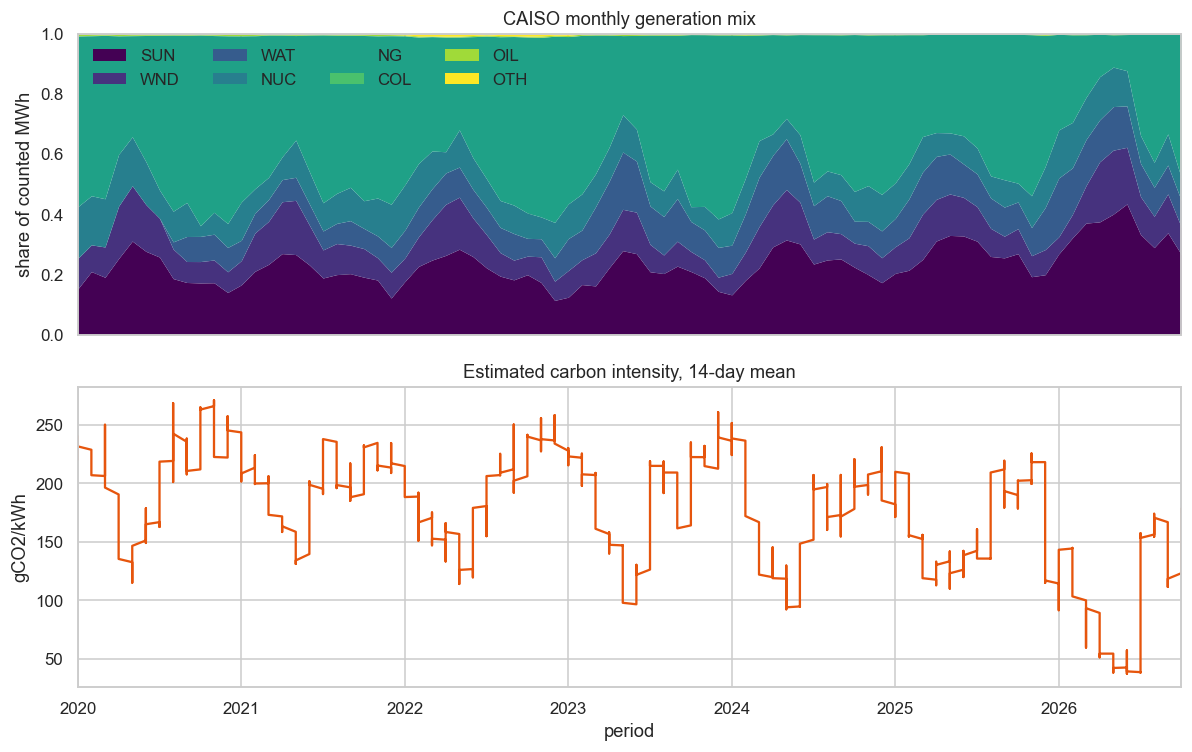

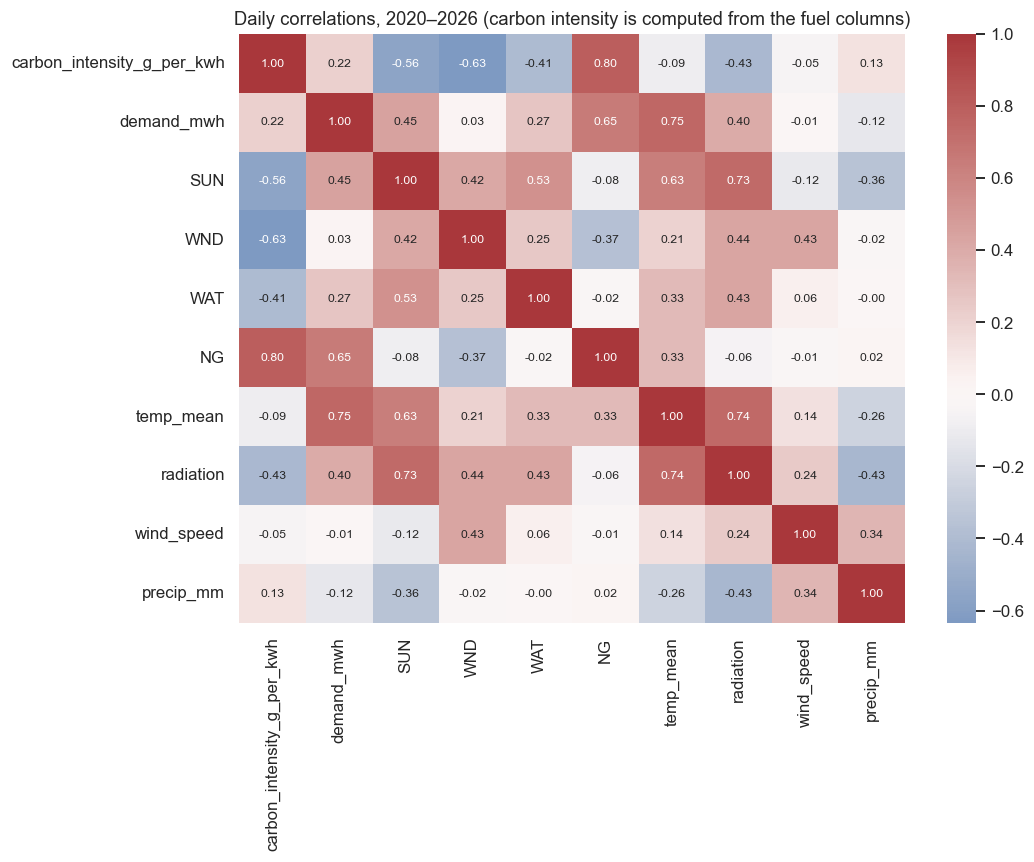

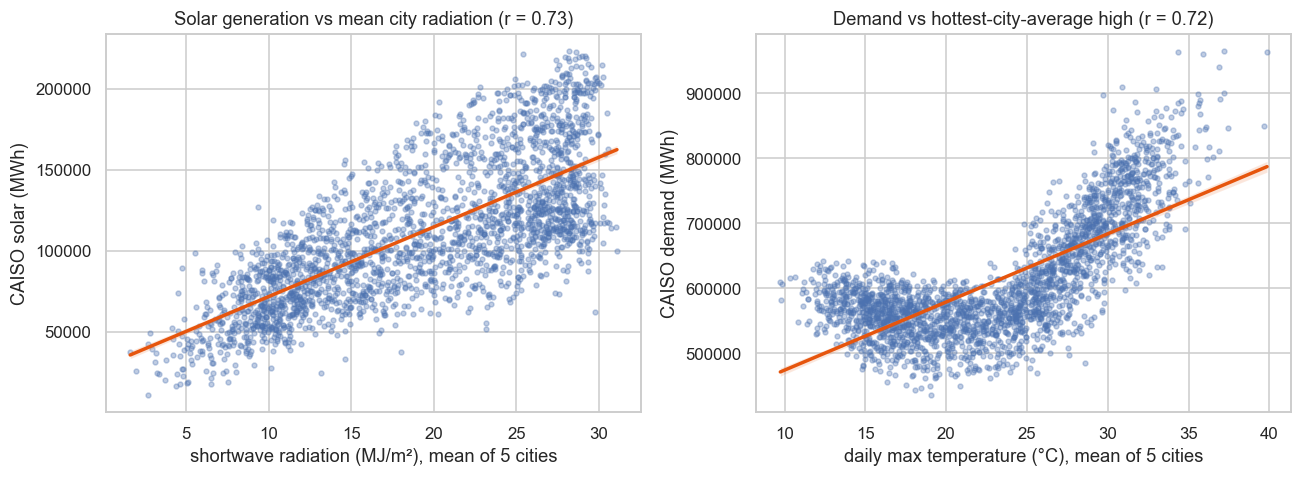

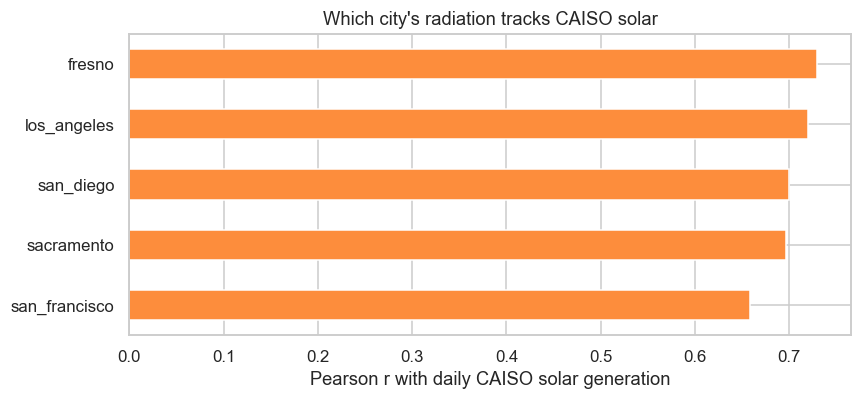

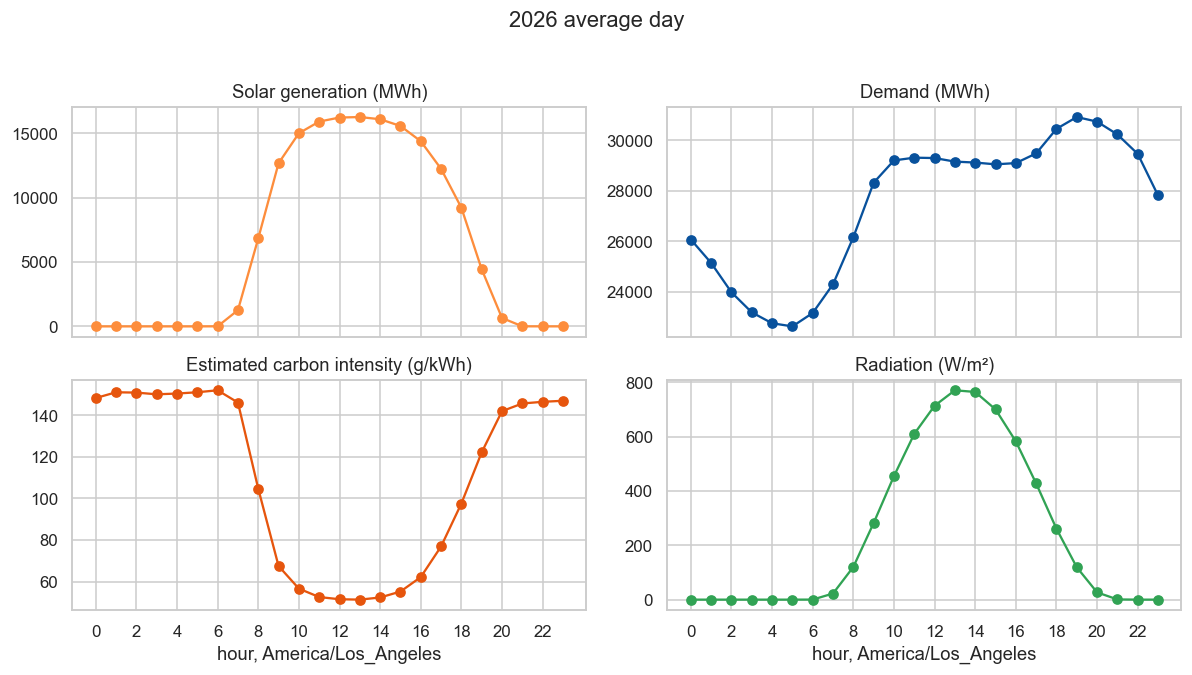

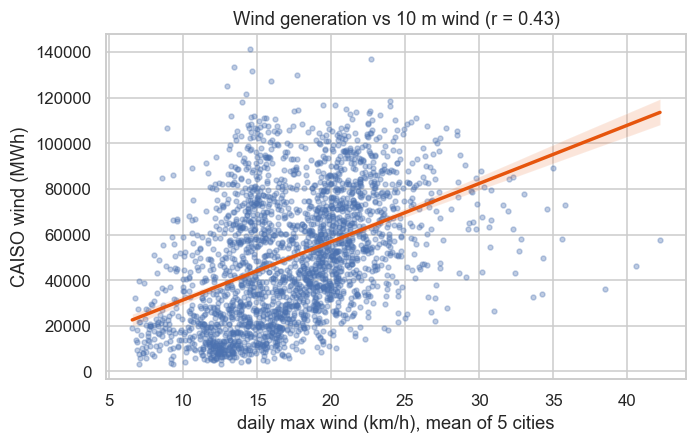

In [6]:
def pair_table(frame: pd.DataFrame, pairs: list, by=None) -> pd.DataFrame:
    rows = []
    working = frame.dropna(subset=[left for left, _ in pairs] + [right for _, right in pairs], how="all").copy()
    adjusted = working.copy()
    if by is not None:
        for column in {name for pair in pairs for name in pair}:
            adjusted[column] = adjusted[column] - adjusted.groupby(by)[column].transform("mean")
    for left, right in pairs:
        rows.append(
            {
                "pair": f"{left} vs {right}",
                "raw_r": working[left].corr(working[right]),
                "adjusted_r": adjusted[left].corr(adjusted[right]) if by is not None else np.nan,
            }
        )
    return pd.DataFrame(rows)


daily_pairs = [
    ("radiation", "SUN"),
    ("wind_speed", "WND"),
    ("temp_mean", "demand_mwh"),
    ("temp_max", "demand_mwh"),
    ("radiation", "carbon_intensity_g_per_kwh"),
    ("temp_mean", "carbon_intensity_g_per_kwh"),
    ("wind_speed", "carbon_intensity_g_per_kwh"),
    ("demand_mwh", "carbon_intensity_g_per_kwh"),
    ("demand_forecast_mwh", "demand_mwh"),
    ("SUN", "carbon_intensity_g_per_kwh"),
    ("NG", "carbon_intensity_g_per_kwh"),
]
hourly_pairs = [
    ("radiation", "SUN"),
    ("wind_100m", "WND"),
    ("wind_10m", "WND"),
    ("temp", "demand_mwh"),
    ("radiation", "carbon_intensity_g_per_kwh"),
    ("cloud", "carbon_intensity_g_per_kwh"),
    ("temp", "carbon_intensity_g_per_kwh"),
    ("demand_mwh", "carbon_intensity_g_per_kwh"),
    ("demand_forecast_mwh", "demand_mwh"),
]
print("Daily correlations. adjusted_r removes the calendar-month mean.")
display(pair_table(daily_panel, daily_pairs, by="month").round(3))
print("Hourly correlations for 2026. adjusted_r removes the hour-of-day mean.")
display(pair_table(hourly_panel, hourly_pairs, by="hour_local").round(3))

monthly = daily_panel[["SUN", "WND", "WAT", "NUC", "NG", "COL", "OIL", "OTH"]].clip(lower=0).resample("MS").sum()
monthly_share = monthly.div(monthly.sum(axis=1), axis=0)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
monthly_share.plot.area(ax=axes[0], linewidth=0, colormap="viridis")
axes[0].set_ylabel("share of counted MWh")
axes[0].set_title("CAISO monthly generation mix")
axes[0].legend(ncol=4, frameon=False)
axes[0].set_ylim(0, 1)
daily_panel["carbon_intensity_g_per_kwh"].rolling(14, min_periods=7).mean().plot(ax=axes[1], color="#e6550d")
axes[1].set_ylabel("gCO2/kWh")
axes[1].set_title("Estimated carbon intensity, 14-day mean")
fig.tight_layout()

heat_cols = [
    "carbon_intensity_g_per_kwh",
    "demand_mwh",
    "SUN",
    "WND",
    "WAT",
    "NG",
    "temp_mean",
    "radiation",
    "wind_speed",
    "precip_mm",
]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    daily_panel[heat_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    ax=ax,
    annot_kws={"size": 8},
)
ax.set_title("Daily correlations, 2020–2026 (carbon intensity is computed from the fuel columns)")
fig.tight_layout()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
r_sun = daily_panel["radiation"].corr(daily_panel["SUN"])
r_dem = daily_panel["temp_max"].corr(daily_panel["demand_mwh"])
sns.regplot(data=daily_panel, x="radiation", y="SUN", ax=axes[0], scatter_kws={"s": 10, "alpha": 0.35}, line_kws={"color": "#e6550d"})
axes[0].set_title(f"Solar generation vs mean city radiation (r = {r_sun:.2f})")
axes[0].set_xlabel("shortwave radiation (MJ/m²), mean of 5 cities")
axes[0].set_ylabel("CAISO solar (MWh)")
sns.regplot(
    data=daily_panel,
    x="temp_max",
    y="demand_mwh",
    ax=axes[1],
    scatter_kws={"s": 10, "alpha": 0.35},
    line_kws={"color": "#e6550d"},
)
axes[1].set_title(f"Demand vs hottest-city-average high (r = {r_dem:.2f})")
axes[1].set_xlabel("daily max temperature (°C), mean of 5 cities")
axes[1].set_ylabel("CAISO demand (MWh)")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(8, 3.8))
city_vs_solar.sort_values().plot.barh(ax=ax, color="#fd8d3c")
ax.set_xlabel("Pearson r with daily CAISO solar generation")
ax.set_title("Which city's radiation tracks CAISO solar")
fig.tight_layout()

profile = hourly_panel.groupby("hour_local")[["SUN", "demand_mwh", "carbon_intensity_g_per_kwh", "radiation"]].mean()
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
series = [
    ("SUN", "Solar generation (MWh)", "#fd8d3c"),
    ("demand_mwh", "Demand (MWh)", "#08519c"),
    ("carbon_intensity_g_per_kwh", "Estimated carbon intensity (g/kWh)", "#e6550d"),
    ("radiation", "Radiation (W/m²)", "#31a354"),
]
for ax, (column, label, color) in zip(axes.ravel(), series):
    ax.plot(profile.index, profile[column], color=color, marker="o")
    ax.set_title(label)
    ax.set_xticks(range(0, 24, 2))
axes[1, 0].set_xlabel("hour, America/Los_Angeles")
axes[1, 1].set_xlabel("hour, America/Los_Angeles")
fig.suptitle("2026 average day", y=1.02)
fig.tight_layout()

r_wind = daily_panel["wind_speed"].corr(daily_panel["WND"])
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.regplot(data=daily_panel, x="wind_speed", y="WND", ax=ax, scatter_kws={"s": 10, "alpha": 0.35}, line_kws={"color": "#e6550d"})
ax.set_title(f"Wind generation vs 10 m wind (r = {r_wind:.2f})")
ax.set_xlabel("daily max wind (km/h), mean of 5 cities")
ax.set_ylabel("CAISO wind (MWh)")
fig.tight_layout()


CAISO solar columns ['ACTUAL', 'DAM'] hours 336
solar forecast r all hours 0.996, daytime 0.973


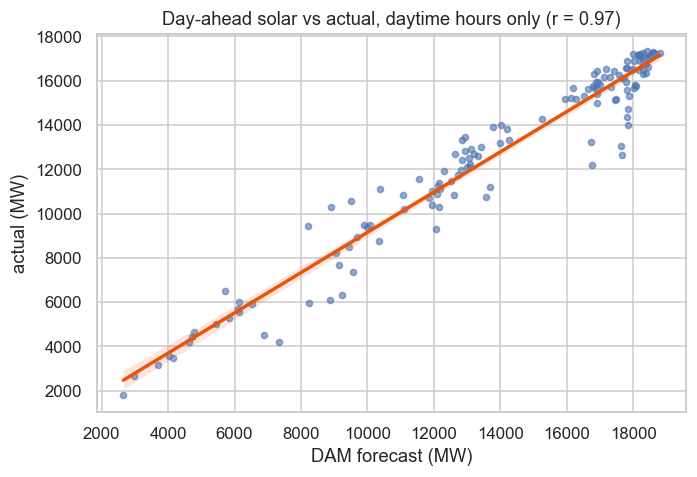

In [7]:
if caiso_renewables is None or caiso_renewables.empty:
    print("No CAISO forecast frame to compare.")
else:
    solar = caiso_renewables[caiso_renewables["renewable_type"] == "Solar"]
    wide = solar.pivot_table(index="time_utc", columns="market", values="mw", aggfunc="sum")
    print("CAISO solar columns", list(wide.columns), "hours", len(wide))
    if {"DAM", "ACTUAL"} <= set(wide.columns):
        wide = wide.copy()
        wide["hour_local"] = wide.index.tz_convert("America/Los_Angeles").hour
        daytime = wide[wide["hour_local"].between(8, 17)]
        r_all = wide["DAM"].corr(wide["ACTUAL"])
        r_day = daytime["DAM"].corr(daytime["ACTUAL"])
        print(f"solar forecast r all hours {r_all:.3f}, daytime {r_day:.3f}")
        fig, ax = plt.subplots(figsize=(6.5, 4.5))
        sns.regplot(data=daytime, x="DAM", y="ACTUAL", ax=ax, scatter_kws={"s": 16, "alpha": 0.6}, line_kws={"color": "#e6550d"})
        ax.set_title(f"Day-ahead solar vs actual, daytime hours only (r = {r_day:.2f})")
        ax.set_xlabel("DAM forecast (MW)")
        ax.set_ylabel("actual (MW)")
        fig.tight_layout()
    else:
        display(wide.head())


## What to carry into a model

The target EcoShift actually wants is still an external hourly gCO₂/kWh series from Electricity Maps, or a marginal series from WattTime. Until one of those tokens is in `.env`, the carbon number in this notebook is the public stand-in: CAISO gas, coal, and oil, divided by fossil plus nuclear, hydro, solar, and wind. On the 2026 average day that estimate falls from about 150 g/kWh overnight to about 50 g/kWh around noon, which is the solar shape.

Measured on this pull (daily is 2020–2026, hourly is 2026):

| Relationship | Raw r | After removing the calendar cycle |
| --- | --- | --- |
| Hourly radiation vs CAISO solar | 0.93 | 0.74 (hour of day removed) |
| Daily radiation vs CAISO solar | 0.73 | 0.32 (month removed) |
| Daily max temperature vs demand | 0.72 | 0.46 |
| Hourly temperature vs demand | 0.76 | 0.74 |
| Hourly 10 m wind vs CAISO wind | 0.42 | 0.52 |
| Day-ahead demand forecast vs demand | 0.97 daily, 0.85 hourly | 0.91 daily, 0.96 hourly |
| Hourly radiation vs estimated carbon intensity | −0.57 | −0.18 |
| Gas generation vs estimated carbon intensity | 0.80 | 0.82 |

Fresno radiation tracks daily CAISO solar best (r = 0.73), then Los Angeles (0.72). San Diego is 0.70. San Francisco is the weak one at 0.66. Use a Valley or Los Angeles series, not the coast alone.

Gas versus this carbon estimate is mostly the formula. Do not put both in one model as if they were separate measurements.

A first hourly model can use hour of day, solar radiation, temperature, the CAISO day-ahead demand forecast (`demand_forecast_mwh`), and the CAISO day-ahead solar forecast in `caiso_renewables` where `market` is `DAM`. For Oct 4–17 the solar forecast matches actuals at r = 0.996 across all hours and r = 0.97 for 8am–5pm. Nights are zero on both sides, so the daytime number is the one to trust, and two weeks is a short score.

Hold out a later month. Neighboring hours share the same weather system.
